#Make sure to upload `Riyadh Marathon Results.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Riyadh Marathon Results.csv')
df.head()

,Unnamed: 0,Rank,Gender Rank,Name,Gender,Category,Nationality,Gun Time,Chip Time,Speed,Pace,Distance
0,0,46 / 2285,1 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:42:59.556,00:42:57.505,13.9 Km/Hr,4:17 min/km,10 KM
1,1,53 / 2285,2 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/CZ.gif],00:43:28.175,00:43:24.774,13.8 Km/Hr,4:20 min/km,10 KM
2,2,55 / 2285,3 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:44:00.251,00:43:56.317,13.6 Km/Hr,4:23 min/km,10 KM
3,3,88 / 2285,4 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/MA.gif],00:48:28.115,00:48:22.908,12.4 Km/Hr,4:50 min/km,10 KM
4,4,93 / 2285,5 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:58:37.753,00:48:27.714,12.3 Km/Hr,4:50 min/km,10 KM


#1- Distance vs Speed

* Clean the Speed column (if not already cleaned).

* Calculate the average speed for each Distance.

* Plot a bar chart showing average speed by Distance.

* Which distance category has the highest average speed?

* Why do you think that happens?

In [3]:
df['Speed_clean'] = pd.to_numeric(df['Speed'].str.replace('Km/Hr', '', regex=False).str.strip(), errors='coerce')

In [4]:
avg_speed = df.groupby('Distance')['Speed_clean'].mean().dropna().sort_values()
print(avg_speed)

Distance
4 KM        6.522652
10 KM       7.923597
21.1 KM     8.843178
42.2 KM    10.651626
Name: Speed_clean, dtype: float64


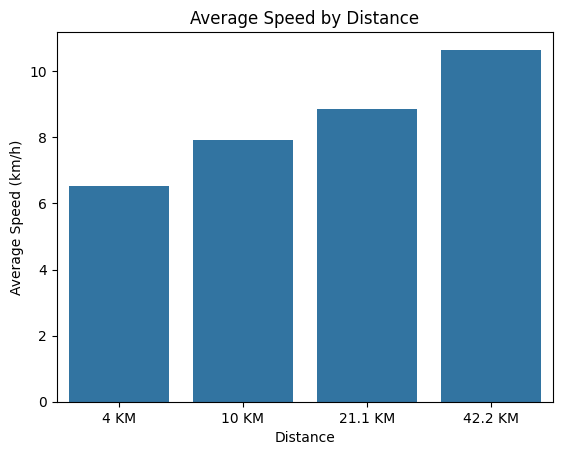

In [5]:
sns.barplot(x=avg_speed.index, y=avg_speed.values)
plt.title('Average Speed by Distance')
plt.xlabel('Distance')
plt.ylabel('Average Speed (km/h)')
plt.show()

In [6]:
# 42.2 KM has the highest average speed (10.65 km/h). marathon runners may be more experienced, while shorter races may attract casual participants.

# 2 — Distance vs Chip Time

* Convert Chip Time to seconds.

* Calculate mean Chip Time for each Distance.

* Create a boxplot of Chip Time by Distance.

* Which distance has the largest variability in time?

* Explain why.

In [7]:
df['Chip_Time_clean'] = pd.to_timedelta(df['Chip Time'], errors='coerce').dt.total_seconds()
print(df.groupby('Distance')['Chip_Time_clean'].mean().dropna())

Distance
10 KM       4879.074216
21.1 KM     9205.610109
4 KM        2447.899938
42.2 KM    15329.598215
Name: Chip_Time_sec, dtype: float64


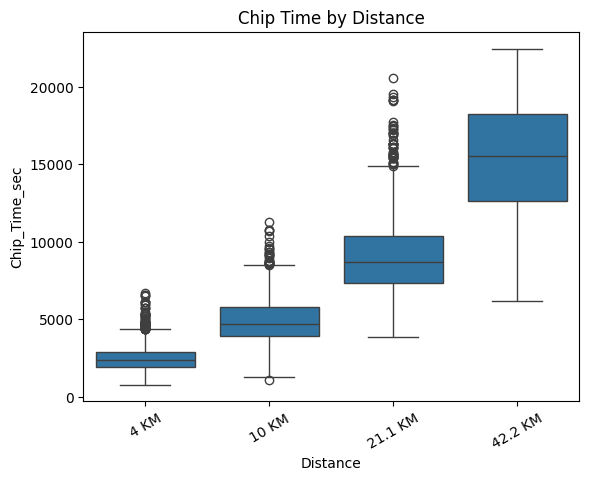

Most variable: 42.2 KM


In [8]:
sns.boxplot(data=df, x='Distance', y='Chip_Time_clean', order=['4 KM','10 KM','21.1 KM','42.2 KM'])
plt.title('Chip Time by Distance')
plt.xticks(rotation=30)
plt.show()
print('Most variable:', df.groupby('Distance')['Chip_Time_clean'].std().idxmax())

In [9]:
# 42.2 KM has the largest standard deviation (about 3,814 seconds)

# 3 — Nationality vs Speed (Top 5 Only)

* Identify the top 5 most frequent nationalities.

* Filter the dataset to include only those nationalities.

* Compute the average speed per nationality.

* Create a bar chart.

* Which nationality has the highest average speed?

In [10]:
df['Nationality_clean'] = df['Nationality'].str.extract(r'flags/([A-Z]+)\.gif')
top5 = df['Nationality_clean'].value_counts().head(5).index
subset = df[df['Nationality_clean'].isin(top5)]
mean_nat = subset.groupby('Nationality_clean')['Speed_clean'].mean().sort_values(ascending=False)
print(mean_nat)

Nationality_clean
GB    8.604286
EG    8.173786
SA    7.703855
IN    6.972803
PH    6.524336
Name: Speed_clean, dtype: float64


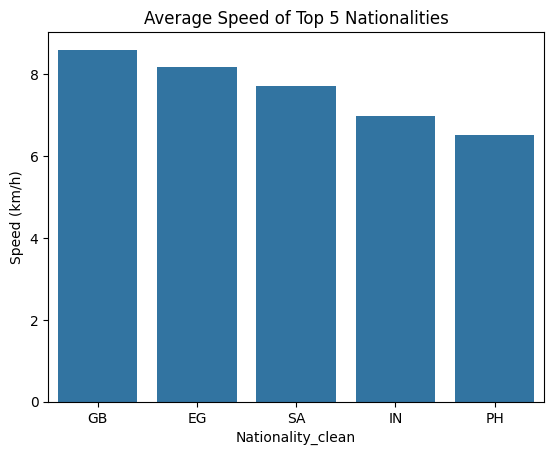

Highest: GB


In [11]:
sns.barplot(x=mean_nat.index, y=mean_nat.values)
plt.title('Average Speed of Top 5 Nationalities')
plt.ylabel('Speed (km/h)')
plt.show()
print('Highest:', mean_nat.idxmax())

In [12]:
# GB (United Kingdom) has the highest mean speed among the five most frequent nationalities (about 8.60 km/h).

# 4 — Speed vs Pace Relationship

* Clean both Speed and Pace columns.

* Convert Pace to minutes as a numeric value.

* Plot scatter plot of Speed vs Pace.

* Is the relationship positive or negative?

* Does this relationship make logical sense?

In [13]:
parts = df['Pace'].str.extract(r'(\d+):(\d+)')
df['Pace_min'] = pd.to_numeric(parts[0], errors='coerce') + pd.to_numeric(parts[1], errors='coerce') / 60

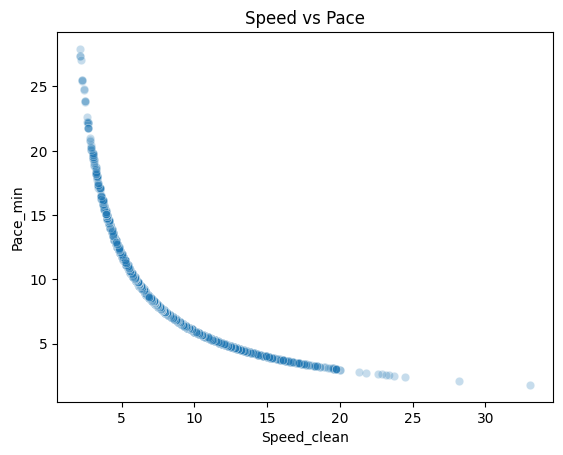

Correlation: -0.8798458599811981


In [14]:
sns.scatterplot(data=df, x='Speed_clean', y='Pace_min', alpha=0.25)
plt.title('Speed vs Pace')
plt.show()
print('Correlation:', df['Speed_clean'].corr(df['Pace_min']))

In [15]:
# the relationship is strongly negative

# 5 — Critical Thinking Question

* Write 8–10 lines answering:

* Which variable seems most important for predicting race performance?

* Which relationship was weakest?

* Were there any surprising results?


In [16]:
# speed is useful for understanding performance, especially within the same race distance.
# Chip Time directly measures how long a runner took to finish.
# Distance must be considered because longer races take more time.
# Speed and pace show a strong negative correlation.
# Speed and raw Chip Time have a weak overall linear correlation.
# mixing different race distances helps explain why this overall correlation is weak.
# surprisingly the 42.2 KM runners had the highest average speed.
# the marathon also had the largest variability in finishing times.